# Figure S7 - Predicted hydrodynamic radii for DDX4 NTD variants

**What the figure shows.** The STARLING-derived mean hydrodynamic radius for wild-type DDX4 NTD and the three phase-separation-deficient variants, with the experimental DLS value (42 Angstroms) drawn as a dashed line.

**What it tells you.** This is the one-number consequence of Figure S6. Each variant removes one class of intramolecular interaction - **24RtoK** removes cation-pi by replacing arginines with lysines, **14FtoA** removes cation-pi and pi-pi by replacing phenylalanines with alanines, and **37EDtoA** removes electrostatics by replacing acidic residues with alanine - and in every case the loss of long-range contacts seen in the scaling maps is accompanied by an increase in overall chain dimensions. The wild-type is the most compact sequence of the four.

The logic the paper draws from this is that the same interactions which compact the *single* chain are the ones that hold *multiple* chains together in a condensate: all three variants are phase-separation deficient, and all three expand.

> **Note on this panel.** The published version of this figure has the 24RtoK and 14FtoA bars mislabelled - the two are swapped relative to the underlying data. This notebook plots them correctly, with each bar carrying the value belonging to its label. See "Differences from the published figure" at the end.

**How it is made.** Ensembles were generated with [STARLING](https://github.com/idptools/starling); $R_h$ is the ensemble-average hydrodynamic radius reported by the ensemble object, using the default Nygaard *et al.* estimator.

## What is in this directory

| path | contents |
|------|----------|
| `figures/` | output; the notebook writes `figure_S7_variant_rh.pdf` and `.png` |

This figure has no data files of its own. It reads four STARLING ensembles (~1.5 GB together) from the shared `data/` directory at the root of `perets_2025`, which is **not tracked by git** - see [`../data/README.md`](../data/README.md).

## Setup

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

# ---------------------------------------------------------------------------
# Holehouse lab figure defaults (December 2024)
# ---------------------------------------------------------------------------

# export PDF/PS fonts as TrueType so text stays editable in Illustrator/Affinity
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

matplotlib.rcParams['axes.linewidth'] = 0.5
matplotlib.rcParams['lines.linewidth'] = 0.8

matplotlib.rcParams['xtick.major.size'] = 2
matplotlib.rcParams['xtick.minor.size'] = 0.5
matplotlib.rcParams['ytick.major.size'] = 2
matplotlib.rcParams['ytick.minor.size'] = 0.5
matplotlib.rcParams['xtick.major.width'] = 0.375
matplotlib.rcParams['ytick.major.width'] = 0.375
matplotlib.rcParams['xtick.minor.width'] = 0.375
matplotlib.rcParams['ytick.minor.width'] = 0.375
matplotlib.rcParams['xtick.major.pad'] = 1
matplotlib.rcParams['ytick.major.pad'] = 1

matplotlib.rcParams['xtick.labelsize'] = 8
matplotlib.rcParams['ytick.labelsize'] = 8
matplotlib.rcParams['axes.labelsize'] = 10
matplotlib.rcParams['legend.fontsize'] = 8

# The manuscript figures used Arial; the fallbacks let this run anywhere.
matplotlib.rcParams['font.family'] = 'sans-serif'
matplotlib.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans']

%matplotlib inline
%config InlineBackend.figure_format = 'retina'

from starling import load_ensemble

In [2]:
import os

DATA_DIR = os.environ.get('PERETS_DATA_DIR', '../data')
STARLING_DIR = os.path.join(DATA_DIR, 'starling')

os.makedirs('figures', exist_ok=True)

# (label, filename, bar colour) - order here is the order along the x-axis
VARIANTS = [
    ('WT',      'ddx4_wt.starling',      'k'),
    ('24RtoK',  'ddx4_24RtoK.starling',  'grey'),
    ('14FtoA',  'ddx4_14FtoA.starling',  'lightgreen'),
    ('37EDtoA', 'ddx4_37EDtoA.starling', 'lightblue'),
]

RH_EXPERIMENTAL = 42   # DLS, this work

for label, filename, _ in VARIANTS:
    path = os.path.join(STARLING_DIR, filename)
    status = 'found' if os.path.isfile(path) else 'MISSING - see ../data/README.md'
    print(f'{label:<9} {filename:<26} [{status}]')

WT        ddx4_wt.starling           [found]
24RtoK    ddx4_24RtoK.starling       [found]
14FtoA    ddx4_14FtoA.starling       [found]
37EDtoA   ddx4_37EDtoA.starling      [found]


## Compute the hydrodynamic radii

Each label is tied to its filename in the `VARIANTS` table above, and the values are collected by iterating over that table - so a bar cannot end up carrying another variant's number.

In [3]:
rh_values = []

for label, filename, _ in VARIANTS:
    ensemble = load_ensemble(os.path.join(STARLING_DIR, filename))
    rh = ensemble.hydrodynamic_radius(return_mean=True)
    rh_values.append(rh)
    print(f'{label:<9} {len(ensemble):>5,} conformers, {len(ensemble.sequence):>3} residues, Rh = {rh:.2f} A')

rh_values = np.array(rh_values)

print()
print(f'wild-type is the most compact: {rh_values[0]:.2f} A')
for (label, _, _), value in zip(VARIANTS[1:], rh_values[1:]):
    print(f'  {label:<9} expands by {value - rh_values[0]:+.2f} A')

WT        1,600 conformers, 245 residues, Rh = 41.33 A
24RtoK    1,600 conformers, 236 residues, Rh = 43.55 A


14FtoA    1,600 conformers, 245 residues, Rh = 43.88 A


37EDtoA   1,600 conformers, 245 residues, Rh = 43.47 A

wild-type is the most compact: 41.33 A
  24RtoK    expands by +2.21 A
  14FtoA    expands by +2.55 A
  37EDtoA   expands by +2.14 A


## The figure

The dashed line is the experimental DLS value for the wild-type; the variants were not measured by DLS, so it is a reference point rather than a comparison for every bar.

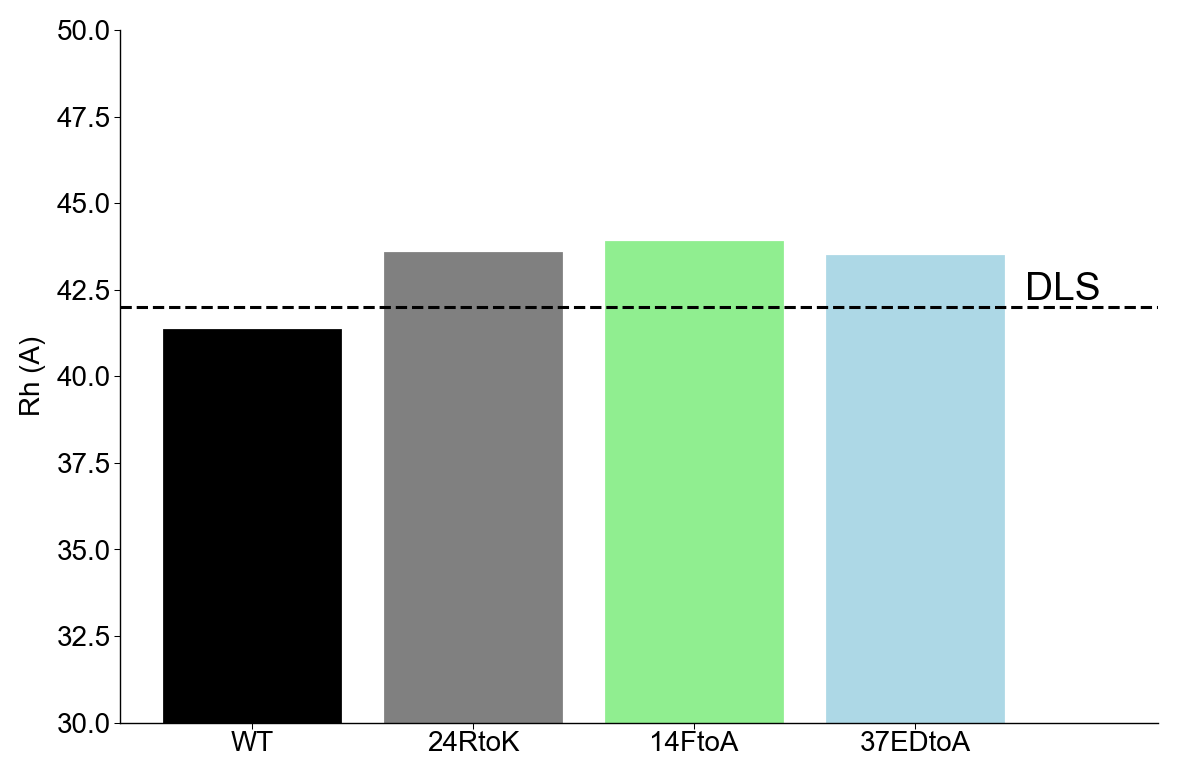

In [4]:
labels = [label for label, _, _ in VARIANTS]
colours = [colour for _, _, colour in VARIANTS]

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(labels, rh_values)

for bar, colour in zip(bars, colours):
    bar.set_color(colour)

ax.set_ylim([30, 50])
ax.set_xlim([-0.6, 4.1])
ax.spines[['top', 'right']].set_visible(False)

# experimental value for the wild-type
ax.axhline(y=RH_EXPERIMENTAL, color='k', lw=1.1, ls='--')
ax.text(3.5, RH_EXPERIMENTAL + 0.2, 'DLS', fontsize=14)

ax.set_ylabel('Rh (A)')
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout()

plt.savefig('figures/figure_S7_variant_rh.pdf')
plt.savefig('figures/figure_S7_variant_rh.png', dpi=350)
plt.show()

## Differences from the published figure

* **The 24RtoK and 14FtoA bars are swapped in the published panel.** In the original notebook the array of values was assembled in the order wild-type, 14FtoA, 24RtoK, 37EDtoA, but the label list passed to the bar chart read wild-type, 24RtoK, 14FtoA, 37EDtoA. The two middle bars therefore carry each other's labels in the published figure, which shows 24RtoK at 43.9 Angstroms and 14FtoA at 43.6 Angstroms. The correct values are **24RtoK = 43.55 Angstroms** and **14FtoA = 43.88 Angstroms**.

  This notebook binds each label to its filename in a single table and iterates over it, so the two cannot come apart. Nothing else about the panel changes, and none of the paper's conclusions depend on the ordering - all three variants expand relative to wild-type either way, which is the point the figure is making.

* **Axis label.** The y-axis reads `Rh (A)` as in the original; the published panel renders it as $R_h$ in Angstroms, set in the vector graphics editor.